# F4, F5, F6, F8: occupations, k-point weights, spectrum normalization (upcoming)

| finding | what | checked here with |
|---|---|---|
| F4 | `fillings` dump is ×2 for `spintype no-spin`, while computed occupations are in [0,1] | any no-spin fixture in `example_calc_dirs` (none yet) |
| F5 | `get_wk_t` drops symmetry weights for spin-polarized reduced meshes | a synthetic `kPts` file |
| F6 | Gaussian kernel unnormalized; LTI applies 1/N_k twice | N2 DOS, and a synthetic dispersive band through `get_lti_spectrum` |
| F8 | `calculate_filling_nobroad` inverted; Gauss/MP1/cold helpers crash on arrays | the helpers vs. JDFTx's `ElecInfo::smear` |

Each section detects whether its fix has landed, from the legacy switch (F4–F6) or from behaviour (F8). Known-bug
checks document the current state and stop being reached once the fix lands.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))  # fixcompare.py lives next to this notebook (run with this directory as cwd)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from fixcompare import *
from crawfish.funcs.general import SIGMA_DEFAULT
import tempfile
from scipy.special import erfc
from scipy.integrate import trapezoid
from crawfish.funcs import get_dos
from crawfish.core.operations.vector import get_lti_spectrum
from crawfish.io.data_parsing import get_wk_t, get_nspin_from_outfile_filepath
from crawfish.core import elecdata as ed_mod
from crawfish.utils.testing import EXAMPLE_CALC_DIRS_DIR

print({f: fix_available(f) for f in ["F4", "F5", "F6"]})

{'F4': False, 'F5': False, 'F6': False}


## F6: spectrum normalization

The integral of the total DOS over all energies should be $\sum_t w_t \cdot n_\text{bands}$, the number of states
(30 here). The reference normalizes crawfish's Gaussian by $1/\sqrt{\pi\,\sigma}$.

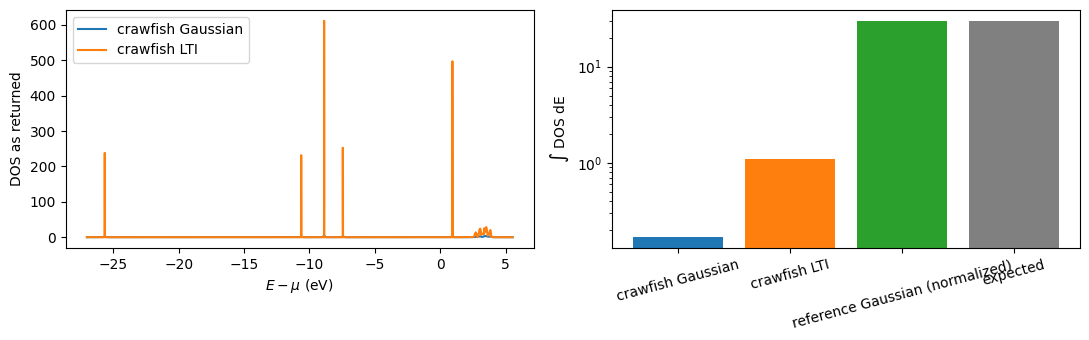

crawfish Gaussian                   0.1681
crawfish LTI                        1.1000
reference Gaussian (normalized)    30.0000
expected                           30.0000
dtype: float64

In [2]:
edata = load_edata()
SIG = SIGMA_DEFAULT
erange = np.arange(edata.e_tj.min() - 0.05, edata.e_tj.max() + 0.05, 0.0002, dtype=np.float32)
expected = float(edata.wk_t.sum() * edata.nbands)
_, dos_g = get_dos(edata, erange=erange, sig=SIG)
_, dos_l = get_dos(edata, erange=erange, lti=True, rattle_eigenvals=True)
dos_g_ref = np.asarray(dos_g) / np.sqrt(np.pi * SIG)
integrals = {"crawfish Gaussian": trapezoid(dos_g, erange), "crawfish LTI": trapezoid(dos_l, erange),
             "reference Gaussian (normalized)": trapezoid(dos_g_ref, erange), "expected": expected}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
x = to_ev_rel_mu(edata, erange)
axes[0].plot(x, dos_g, label="crawfish Gaussian")
axes[0].plot(x, dos_l, label="crawfish LTI")
axes[0].set_ylabel("DOS as returned")
axes[0].set_xlabel(r"$E - \mu$ (eV)")
axes[0].legend()
axes[1].bar(list(integrals), list(integrals.values()), color=["C0", "C1", "C2", "gray"])
axes[1].set_yscale("log")
axes[1].set_ylabel(r"$\int$ DOS dE")
axes[1].tick_params(axis="x", labelrotation=15)
fig.tight_layout()
savefig(fig, "F6_dos_normalization_n2")
plt.show()
pd.Series(integrals).round(4)

N2's bands are flat (an isolated molecule), which LTI resolves poorly. The LTI double counting is clearer on a
dispersive band, so a cosine band on a 6×6×6 grid goes straight through crawfish's `get_lti_spectrum`. With
k-weighted input (what crawfish passes today) the integral is 1/N_k per band instead of 1.

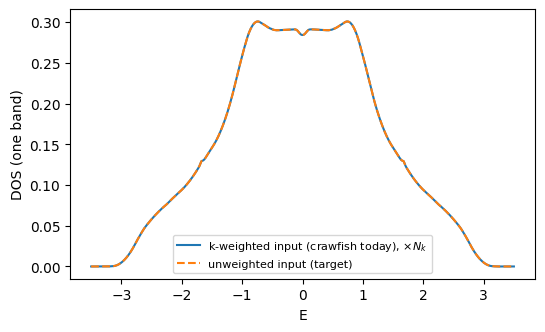

{'k-weighted': np.float32(0.0046296306), 'unweighted': np.float32(1.0000002)}

In [3]:
ng = 6
k = np.stack(np.meshgrid(*[np.arange(ng) / ng] * 3, indexing="ij"), -1)
eig = (np.cos(2 * np.pi * k[..., 0]) + np.cos(2 * np.pi * k[..., 1]) + np.cos(2 * np.pi * k[..., 2]))
e_sabcj = eig[None, ..., None].astype(np.float32)
e0 = np.linspace(-3.5, 3.5, 1401, dtype=np.float32)
w_k = np.full(e_sabcj.shape, 1 / ng**3, dtype=np.float32)  # k-weights for one spin channel
lti_kweighted = np.asarray(get_lti_spectrum(e_sabcj, e0, w_k, np.eye(3))[0])
lti_unweighted = np.asarray(get_lti_spectrum(e_sabcj, e0, np.ones_like(w_k), np.eye(3))[0])
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(e0, lti_kweighted * ng**3, label=r"k-weighted input (crawfish today), $\times N_k$")
ax.plot(e0, lti_unweighted, "--", label="unweighted input (target)")
ax.set_xlabel("E")
ax.set_ylabel("DOS (one band)")
ax.legend(fontsize=8)
savefig(fig, "F6_lti_double_counting")
plt.show()
lti_integrals = {"k-weighted": trapezoid(lti_kweighted, e0), "unweighted": trapezoid(lti_unweighted, e0)}
lti_integrals

## F8: occupation helpers vs. JDFTx's `ElecInfo::smear`

JDFTx uses $x = (\varepsilon-\mu)/(2\sigma)$. The Fermi function is $\tfrac12(1-\tanh x)$ and the Gaussian
filling is $\tfrac12\operatorname{erfc} x$; MP1 and Cold smearing are defined in the same source. The crawfish
helpers are called on an array, as `ElecData.occ_tj` does. When a helper raises, the reference curve is still
drawn.

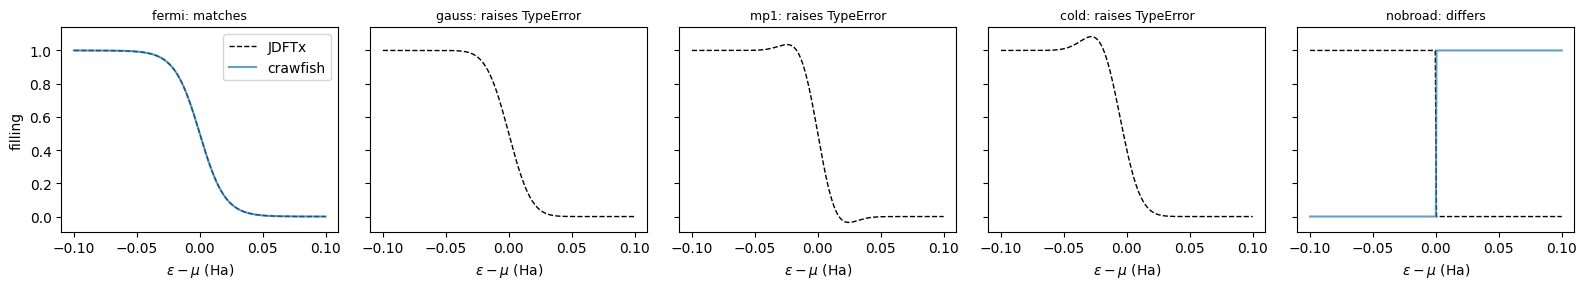

{'fermi': 'matches',
 'gauss': 'raises TypeError',
 'mp1': 'raises TypeError',
 'cold': 'raises TypeError',
 'nobroad': 'differs'}

In [4]:
mu, sigma = 0.0, 0.01
eps = np.linspace(-0.1, 0.1, 401)
xx = (eps - mu) / (2 * sigma)
jdftx = {
    "fermi": 0.5 * (1 - np.tanh(xx)),
    "gauss": 0.5 * erfc(xx),
    "mp1": 0.5 * erfc(xx) - xx * np.exp(-xx**2) / (2 * np.sqrt(np.pi)),
    "cold": 0.5 * erfc(xx + np.sqrt(0.5)) + np.exp(-(xx + np.sqrt(0.5)) ** 2) / np.sqrt(2 * np.pi),
    "nobroad": np.heaviside(mu - eps, 0.5),
}
status = {}
fig, axes = plt.subplots(1, 5, figsize=(16, 3), sharey=True)
for ax, (name, ref_f) in zip(axes, jdftx.items()):
    ax.plot(eps, ref_f, "k--", lw=1, label="JDFTx")
    try:
        got = getattr(ed_mod, f"calculate_filling_{name}")(sigma, eps, mu)
        ax.plot(eps, got, alpha=0.7, label="crawfish")
        status[name] = "matches" if np.allclose(got, ref_f, atol=1e-8) else "differs"
    except Exception as err:
        status[name] = f"raises {type(err).__name__}"
    ax.set_title(f"{name}: {status[name]}", fontsize=9)
    ax.set_xlabel(r"$\varepsilon - \mu$ (Ha)")
axes[0].set_ylabel("filling")
axes[0].legend()
fig.tight_layout()
savefig(fig, "F8_filling_helpers")
plt.show()
status

## F4: fillings file vs. computed occupations

`N2_bare_min` and `N2_no_fillings` are the same z-spin calculation, with and without a `fillings` file, so they
should agree (z-spin fillings aren't doubled). The no-spin comparison runs only once a `spintype no-spin` fixture
with a `fillings` file exists in `example_calc_dirs`.

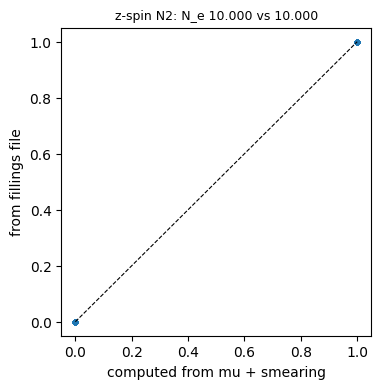

no-spin fixtures with a fillings file: none (F4 can't be demonstrated yet)


{}

In [5]:
with_file, without_file = load_edata(), load_edata(Path(EXAMPLE_CALC_DIRS_DIR) / "N2_no_fillings")
ne = lambda ed: float(np.sum(ed.wk_t[:, None] * ed.occ_tj))
fig, ax = plt.subplots(figsize=(4, 4))
ax.scatter(without_file.occ_tj.ravel(), with_file.occ_tj.ravel(), s=8)
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.set_xlabel("computed from mu + smearing")
ax.set_ylabel("from fillings file")
ax.set_title(f"z-spin N2: N_e {ne(with_file):.3f} vs {ne(without_file):.3f}", fontsize=9)
savefig(fig, "F4_occupations_zspin")
plt.show()

nospin_dirs = [d for d in Path(EXAMPLE_CALC_DIRS_DIR).iterdir()
               if (d / "out").exists() and (d / "fillings").exists()
               and get_nspin_from_outfile_filepath(d / "out") == 1]
print("no-spin fixtures with a fillings file:", [d.name for d in nospin_dirs] or "none (F4 can't be demonstrated yet)")
nospin_ne = {d.name: ne(load_edata(d)) for d in nospin_dirs}
nospin_ne

## F5: k-point weights on a spin-polarized reduced mesh

This is a synthetic `kPts` file with symmetry-reduced, non-uniform weights for two spins. The weights `get_wk_t`
returns for it should be the file's weights.

/var/folders/v3/dhcqls6s33s55hmm47b0wr500000gn/T/ipykernel_38219/1628534155.py:7: UserWarning: Kpts file does not match expected number of k-points. k-point weights will be meaningless.
  returned = get_wk_t(kpts, nspin=2, kfolding=[4, 1, 1], lti=False)


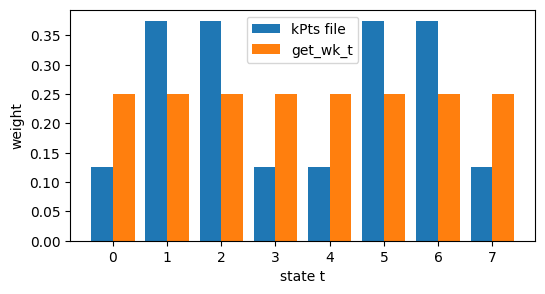

In [6]:
file_w = np.array([0.125, 0.375, 0.375, 0.125] * 2)  # 4 reduced k per spin, each spin sums to 1
with tempfile.TemporaryDirectory() as tmp:
    kpts = Path(tmp) / "kPts"
    kpts.write_text("".join(
        f"{i:5d}  [ +0.0000000 +0.0000000 +{0.25 * (i % 4):.7f} ]  {w:.9f}  spin {1 if i < 4 else -1:+d}\n"
        for i, w in enumerate(file_w)))
    returned = get_wk_t(kpts, nspin=2, kfolding=[4, 1, 1], lti=False)
fig, ax = plt.subplots(figsize=(6, 3))
idx = np.arange(len(file_w))
ax.bar(idx - 0.2, file_w, 0.4, label="kPts file")
ax.bar(idx + 0.2, returned, 0.4, label="get_wk_t")
ax.set_xlabel("state t")
ax.set_ylabel("weight")
ax.legend()
savefig(fig, "F5_reduced_mesh_weights")
plt.show()

## Tests

In [7]:
# F6
if fix_available("F6"):
    assert np.isclose(integrals["crawfish Gaussian"], expected, rtol=0.01)
    # The LTI fix may live in the callers rather than get_lti_spectrum; check the N2 DOS integral by eye
    print("LTI DOS integral after F6:", integrals["crawfish LTI"], "expected", expected, "(flat bands: approximate)")
else:
    assert np.isclose(integrals["reference Gaussian (normalized)"], expected, rtol=0.01)
    assert np.isclose(lti_integrals["unweighted"], 1.0, rtol=0.01)
    assert np.isclose(lti_integrals["k-weighted"], 1 / ng**3, rtol=0.01)  # known bug: extra 1/N_k
    assert not np.isclose(integrals["crawfish Gaussian"], expected, rtol=0.5)  # known bug: unnormalized

# F8: behaviour-based (no legacy switch)
assert status["fermi"] == "matches"
if all(status[n] == "matches" for n in jdftx):
    print("F8 fixed: all helpers match JDFTx.")
else:
    assert status["nobroad"] == "differs" and status["gauss"].startswith("raises"), status  # known bugs

# F4: z-spin data must agree with and without the fillings file
assert np.isclose(ne(with_file), ne(without_file), atol=1e-3)
for name, n in nospin_ne.items():
    print(f"{name}: N_e from fillings file = {n:.3f} (F4 fixed if this equals nElectrons in the outfile)")

# F5
if fix_available("F5"):
    assert np.allclose(returned, file_w)
else:
    assert not np.allclose(returned, file_w)  # known bug: uniform weights returned
print("All F4-F8 checks passed.")

All F4-F8 checks passed.
